> **ANNEX.** **Working notes** of the pattern reviewer, in the order they were produced (includes intermediate results on E1–E4). **The organized, complete version, with the independent test E5, is in `01_FINAL_full_story`.** This keeps the record of the process.
>
> Main reading: `01_FINAL_full_story` · engine: `02_deterministic_engine` · map: `00_INDEX`.

# 04 · Cross-receipt pattern reviewer
## The idea in one sentence
The engine's rules look at **one receipt at a time**. Some traps only show up **when looking at several receipts from the same employee together**. A reviewer (an LLM) reads the history and can **raise** a `pass` to `review`. It never lowers anything, and the verdict still belongs to the deterministic engine.

## Why this is "the meta" of an industry case study
The agent in the industry case study ran **after** the existing model and rules and only reviewed what had already passed. Same here: the engine decides first and the reviewer only looks at the `pass` receipts.

## How we measure it without inventing answers
We **plant the patterns ourselves**, so we know exactly which receipts are suspicious. There are three patterns, all legal for the engine receipt by receipt, but odd as a whole:

| Pattern | What happens | Why per-receipt rules don't see it |
|---|---|---|
| `gift_splitting` | Several gifts to the **same client** on different days, each ≤ <span class="tex2jax_ignore">&#36;</span>50 | GIFT-01 sets the <span class="tex2jax_ignore">&#36;</span>50 cap **per receipt** ("one occasion is one receipt") |
| `duplicate_submission` | The **same expense** submitted twice with different ids | Each copy, on its own, is valid |
| `just_under_threshold` | Several equipment purchases at <span class="tex2jax_ignore">&#36;</span>195–<span class="tex2jax_ignore">&#36;</span>199.9, just under the <span class="tex2jax_ignore">&#36;</span>200 limit that requires pre-approval | TECH-02 only looks at each item separately |

And there are **clean** histories, with deliberately misleading cases (coffee every day, gifts to *different* clients, expensive equipment but with pre-approval) to measure **false alarms**.

## How it will be evaluated
1. Each history is run through the engine, receipt by receipt (with the correct categories). The reviewer can only touch the ones that came out `pass`.
2. An LLM is asked to flag receipts to escalate.
3. Metrics: of the planted receipts, **how many it finds** (recall); of the clean histories, **how many it over-flags** (false alarms).
4. First we test frontier models **with prompt only**. Only if there is room (or if a small local one is of interest) do we fine-tune one.

In [1]:
import json, collections, random
from pathlib import Path
import pandas as pd
ROOT = Path.home()/'finetune_project'/'data_synth'
H = json.load(open(ROOT/'patterns_v1.json'))
rows = []
for h in H:
    pl = set(h['planted_receipts']); ds = collections.Counter(r['_engine']['disposition'] for r in h['receipts'])
    rows.append({'pattern': h['kind'], 'receipts': len(h['receipts']), 'planted': len(pl),
                 'planted that the engine let pass': sum(r['_engine']['disposition'] == 'pass' for r in h['receipts'] if r['receipt_id'] in pl)})
T = pd.DataFrame(rows).groupby('pattern').agg(histories=('receipts', 'size'), receipts=('receipts', 'sum'), planted=('planted', 'sum'), engine_passes=('planted that the engine let pass', 'sum'))
T

,histories,receipts,planted,engine_passes
pattern,,,,
clean,30,279,0,0
duplicate_submission,20,160,20,19
gift_splitting,20,208,68,68
just_under_threshold,20,220,80,80


**Reading:** `planted` are the suspicious receipts the reviewer should find. `engine_passes` says how many of those the engine **let pass**: they are exactly the ones the reviewer can rescue. (If the engine already flagged them, there would be nothing to add.)

## The main argument (quote from an industry case study, Part 1)
> **"We wanted a way to review recent behavior without engineering a new feature for every pattern.** An LLM can compare the current transaction with the supplied history and apply fraud-review guidance expressed in natural language. Updating that guidance does not require retraining the model, although every change still needs validation against transaction outcomes."

**Our finding, with evidence:** there are frauds that the deterministic engine lets pass receipt by receipt and that no anticipated rule catches. We built 8 families of our own and asked 6 agents to invent schemes I had not thought of: **24 new schemes** came out, **and the engine lets 100% pass** (verified). A reviewer with natural-language guidance does not need one rule per pattern.

**The cycle:** the LLM *discovers* and escalates to human review → what is confirmed becomes a deterministic rule. Full record: `finetune/HALLAZGOS_fraudes_que_el_motor_pasa.md`.

In [2]:
RT = [json.loads(x) for x in open(ROOT/'patterns_v2_redteam.jsonl')]
bys = collections.OrderedDict()
for h in RT: bys.setdefault(h['scheme'], []).append(h)
pd.DataFrame([{'scheme': s, 'histories': len(hs), 'planted receipts': sum(len(h['planted_receipts']) for h in hs), 'why it is suspicious': hs[0]['reason'], 'engine': 'all pass'} for s, hs in bys.items()]).set_index('scheme')

,histories,planted receipts,why it is suspicious,engine
scheme,,,,
weekend_client_entertainment_no_trip,7,23,Client Entertainment is claimed repeatedly on ...,all pass
overlapping_lodging_same_night,7,18,Two different hotels are claimed for the same ...,all pass
recurring_item_merchant_rotation,7,30,The same identical office item is bought every...,all pass
trip_id_stretched_over_month,7,24,One trip_id with a 1-2 night duration carries ...,all pass
team_label_for_solo_meals,7,27,Solo lunches repeatedly filed as two-person te...,all pass
personal_goods_as_office_supplies,7,27,Household and personal items described in the ...,all pass
gift_baskets_as_team_meals,7,29,Gourmet hampers bought at gift shops are filed...,all pass
weekend_rides_under_trip_id,7,26,Evening and weekend ride-shares of a personal ...,all pass
sequential_invoice_amounts,7,28,Same vendor billed in an exact arithmetic prog...,all pass


## One history of each type (what the reviewer would see)
The rows highlighted with ◄ are the planted ones; the reviewer does not see that mark.

In [3]:
def show(h):
    pl = set(h['planted_receipts']); out = []
    for r in h['receipts']:
        li = r['line_items']
        out.append({'date': r['transaction_datetime'][:10], 'merchant': r['merchant_name'], 'type': r['submitted_expense_type'],
                    'USD': r['total_amount_usd'], 'lines': ' | '.join(l['description_raw'] for l in li)[:70], 'engine': r['_engine']['disposition'],
                    'planted': '◄' if r['receipt_id'] in pl else ''})
    return pd.DataFrame(out)
for kind in ('gift_splitting', 'duplicate_submission', 'just_under_threshold', 'clean'):
    h = next(x for x in H if x['kind'] == kind)
    print('\n###', kind, '·', h['history_id'], '· employee', h['employee_id'])
    display(show(h))


### gift_splitting · PH001 · employee E-8331


,date,merchant,type,USD,lines,engine,planted
0,2026-05-03,ブンボウグ ハナミズキ,Office Supplies,6.10,ポストカード 10枚セット 無地 風景柄 | ほちきす ハリ 10号 3箱,pass,
1,2026-05-03,The Present Studio,Client Gifts,41.33,Wine-free tea set for client Peter Novak (Acme...,pass,◄
2,2026-05-05,北嶺ゴルフ倶楽部,Meals - Team,942.02,5G対応端末 本体一括払い | 【処方箋医薬品】睡眠導入剤 14日分 | 端末 SH-53 ブルー,pass,
3,2026-05-08,炭火居酒屋 ひなた,Meals - Team,49.18,ビール衣の白身魚フライ | 日替わりランチセット(サービス料込) | お土産 箱入り焼き菓子...,pass,
4,2026-05-09,文具店 ことのは,Office Supplies,41.74,角2封筒 100枚 社名入 | 首都高 ﾂｳｺｳﾘｮｳｷﾝ ETC ﾄｳｷｮｳ→ﾊﾈﾀﾞ |...,pass,
5,2026-05-11,Giftery & Co,Client Gifts,44.23,Branded leather folio for client Peter Novak (...,pass,◄
6,2026-05-12,Sharma Book & Stationery Mart,Office Supplies,11.16,Classmate Notebook 200pg | BOX FILE+PUNCH SET,pass,
7,2026-05-14,緑丘カントリークラブ,Meals - Team,698.81,調剤薬 血圧降下剤 28日分 | ｽﾏﾎ ﾎﾝﾀｲ 128G | 携帯端末 中古 ブラック ...,pass,
8,2026-05-17,紙工房 まるえい,Office Supplies,38.66,ラベルライター用テープ 24mm 白 8m巻 | 発送代行 ダンボール梱包 3個口 | ﾗｯ...,pass,
9,2026-05-21,The Present Studio,Client Gifts,39.21,Wine-free tea set for client Peter Novak (Acme...,pass,◄



### duplicate_submission · PH021 · employee E-8381


,date,merchant,type,USD,lines,engine,planted
0,2026-05-05,Mini Mercado Dois Irmãos,Meals - Team,12.80,ginger beer s/ alcool lata | Coca-Cola 2L | Ou...,pass,
1,2026-05-06,Old Mill Steakhouse,Meals - Team,30.50,Gratuity Add-on for Team Lunch Order | DLVRY/S...,pass,
2,2026-05-07,Papelería Lecumberri,Office Supplies,50.55,CLIPS MARIPOSA #2 C/12 | Pizarrón blanco magné...,pass,
3,2026-05-09,Elm Street Cleaners & Parcel,Office Supplies,21.16,PADDED MAILER | Gift-wrap style kraft roll (br...,pass,
4,2026-05-09,Elm Street Cleaners & Parcel,Office Supplies,21.16,PADDED MAILER | Gift-wrap style kraft roll (br...,pass,◄
5,2026-05-11,Metro Wireless,Meals - Team,294.00,Minor League Baseball Game Ticket Section 112 ...,pass,
6,2026-05-12,Papeterie Dunn,Office Supplies,60.22,carnet cuir + stylo gravé | Impression couleur...,pass,
7,2026-05-17,Cantina El Sol Dorado,Client Entertainment,35.20,Michelada preparada 1L | Cantarito jarro | Vin...,pass,



### just_under_threshold · PH041 · employee E-8120


,date,merchant,type,USD,lines,engine,planted
0,2026-05-01,ブンボウグ ハナミズキ,Office Supplies,6.10,ポストカード 10枚セット 無地 風景柄 | ほちきす ハリ 10号 3箱,pass,
1,2026-05-02,北嶺ゴルフ倶楽部,Meals - Team,942.02,5G対応端末 本体一括払い | 【処方箋医薬品】睡眠導入剤 14日分 | 端末 SH-53 ブルー,pass,
2,2026-05-03,緑丘カントリークラブ,Meals - Team,698.81,調剤薬 血圧降下剤 28日分 | ｽﾏﾎ ﾎﾝﾀｲ 128G | 携帯端末 中古 ブラック ...,pass,
3,2026-05-04,PixelWorks Store,Computer Equipment,197.91,Monitor arm dual,pass,◄
4,2026-05-05,炭火居酒屋 ひなた,Meals - Team,49.18,ビール衣の白身魚フライ | 日替わりランチセット(サービス料込) | お土産 箱入り焼き菓子...,pass,
5,2026-05-06,紙工房 まるえい,Office Supplies,38.66,ラベルライター用テープ 24mm 白 8m巻 | 発送代行 ダンボール梱包 3個口 | ﾗｯ...,pass,
6,2026-05-07,文具店 ことのは,Office Supplies,41.74,角2封筒 100枚 社名入 | 首都高 ﾂｳｺｳﾘｮｳｷﾝ ETC ﾄｳｷｮｳ→ﾊﾈﾀﾞ |...,pass,
7,2026-05-13,Circuit Hub,Computer Equipment,198.40,USB hub 10-port powered,pass,◄
8,2026-05-13,Sharma Book & Stationery Mart,Office Supplies,11.16,Classmate Notebook 200pg | BOX FILE+PUNCH SET,pass,
9,2026-05-22,PixelWorks Store,Computer Equipment,196.85,Monitor arm dual,pass,◄



### clean · PH061 · employee E-8340


,date,merchant,type,USD,lines,engine,planted
0,2026-05-01,Théâtre Saint-Denis Billetterie,Office Supplies,564.29,Téléphone cellulaire Google Pixel 7a noir - of...,pass,
1,2026-05-03,Vivo Mais Celulares,Office Supplies,52.36,Losartana Potássica 50mg c/ 30 comprimidos (re...,pass,
2,2026-05-05,Telcel Centro de Atención,Office Supplies,197.67,Tamoxifeno 20 mg caja con 30 tabs - Rx | clona...,pass,
3,2026-05-10,Metro Wireless,Meals - Team,294.00,Minor League Baseball Game Ticket Section 112 ...,pass,
4,2026-05-11,Casse-Croûte Chez Léo,Meals - Team,18.94,Frais de réservation en ligne | soupe à l'oign...,pass,
5,2026-05-14,Papelería Lecumberri,Office Supplies,50.55,CLIPS MARIPOSA #2 C/12 | Pizarrón blanco magné...,pass,
6,2026-05-18,Centro de Negocios Polanco,Meals - Team,40.70,cuota srv. sala jnt | comida p/ cliente Luis M...,pass,


## Test reviewers (results)
Haiku with prompt only (natural-language guidance, summaries computed by code, can only escalate). The rules were frozen before scoring.

| Exam | Rules A1 (5 families) | Rules A2 (8 families) | **Haiku reviewer** |
|---|---|---|---|
| Already-seen families (E3) | 100 % | 100 % | **88 %** (35/40) |
| Unseen families (E2) | 0 % | 95 % | **78 %** (47/60) |
| Schemes set aside from the red team (E1, 12 schemes) | 0 % | 0 % | **54 %** (45/84; 35 % of the receipts) |
| Clean controls: false alarms (E4) | 0 % | 0 % | **11 %** (10/91) |

**Honest reading:** where the rules see nothing, the LLM with a prompt finds half or more of the histories, but not all; the rules are better on what is already programmed. False alarms dropped from 44 % to 11 % only by fixing defects in my generator (merchants that didn't fit, incoherent trips): the reviewer is very sensitive to oddities, and with real (dirty) data precision will be the challenge.

In [4]:
key = json.load(open(ROOT/'reviewer_sft'/'eval_key.json'))
import glob
pred = {}
for f in glob.glob(str(ROOT/'review_out'/'haiku_rv5*.json')) + glob.glob(str(ROOT/'review_out'/'haiku_rv6[0-5].json')):
    for h in json.load(open(f)):
        if h['history_id'] in key: pred[h['history_id']] = {e['receipt_id'] for e in h.get('escalate', [])}
rows = collections.defaultdict(lambda: [0, 0])
for hid, k in key.items():
    if hid in pred and k['planted']:
        rows[k['family']][1] += 1; rows[k['family']][0] += bool(set(k['planted']) & pred[hid])
print(len(pred), 'histories scored' if pred else 'no results yet')
pd.DataFrame({'detected/histories': {k: f'{v[0]}/{v[1]}' for k, v in sorted(rows.items())}, '%': {k: round(100*v[0]/v[1]) for k, v in sorted(rows.items())}})

184 histories scored


,detected/histories,%
competing_saas_tool_sampling,2/7,29
day_trip_with_lodging,7/7,100
duplicate_submission,20/22,91
gift_splitting,10/10,100
gift_under_naming,6/9,67
identical_booking_fee_across_rides,0/7,0
itemize_just_under,5/5,100
meal_cap_hugging,4/6,67
meal_just_under_doc,17/22,77
office_purchases_exact_multiples,0/7,0


## Our own model (Qwen3-4B fine-tuned as reviewer)
Pre-registered before training (see `FINETUNE_LOG.md`, section 9): it is trained on 36 schemes and 5 families, and tested on **12 schemes and 3 families it never saw**. "Gets close" criterion: detection on E1+E2 ≥ 58.9 % (Haiku 63.9 % minus 5) and false alarms ≤ 16 % (Haiku 11 % plus 5). The results appear in the next section once training finishes on the Mac mini.

## Honest limits
- The patterns are **the ones I imagined**: a model could learn my patterns and not real fraud.
- Only three patterns; real fraud is more varied.
- The filler receipts come from the synthetic dataset and from a small group (the ones the engine lets pass), so they repeat across histories.
- Testing was done in USD and without European receipts to avoid an engine requirement (REG-04 needs an exchange rate in the batch).

## Final result: tuned Qwen3-4B vs Haiku (measured 2026-10-29)
Criteria frozen before measuring: *gets close* = recall E1+E2 ≥ 58.9% and false alarms ≤ 16%; *surpasses* = ≥ 68.9% and ≤ 11%.
**Caveat:** training and evaluation come from the same generator (Claude); a single run; Haiku with an untuned prompt.

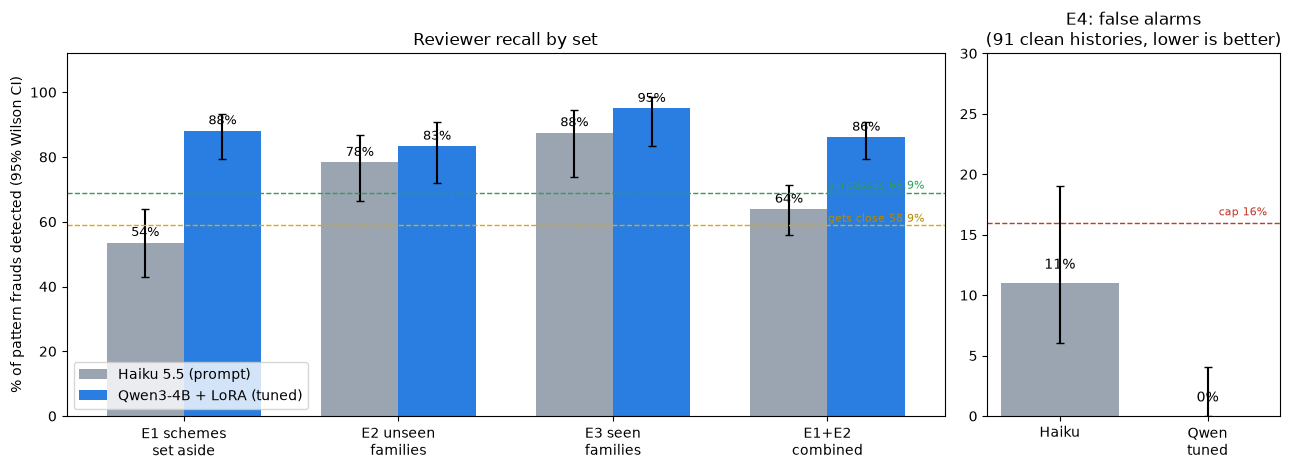

In [5]:
import matplotlib.pyplot as plt, numpy as np
# (detected, total) measured; Haiku = frozen baseline; Qwen = LoRA adapter v1
def wilson(k,n,z=1.96):
    p=k/n; d=1+z*z/n; c=p+z*z/(2*n); m=z*((p*(1-p)/n+z*z/(4*n*n))**.5); return (c-m)/d*100,(c+m)/d*100
sets=["E1 schemes\nset aside","E2 unseen\nfamilies","E3 seen\nfamilies","E1+E2\ncombined"]
hk=[(45,84),(47,60),(35,40),(92,144)]
qw=[(74,84),(50,60),(38,40),(124,144)]
x=np.arange(len(sets)); w=.36
fig,ax=plt.subplots(1,2,figsize=(13,4.8),gridspec_kw={"width_ratios":[3,1]})
for off,data,lab,col in [(-w/2,hk,"Haiku 5.5 (prompt)","#9aa5b1"),(w/2,qw,"Qwen3-4B + LoRA (tuned)","#2a7de1")]:
    v=[100*k/n for k,n in data]; ci=[wilson(k,n) for k,n in data]
    err=[[a-c[0] for a,c in zip(v,ci)],[c[1]-a for a,c in zip(v,ci)]]
    b=ax[0].bar(x+off,v,w,yerr=err,capsize=3,label=lab,color=col)
    for r,a in zip(b,v): ax[0].text(r.get_x()+r.get_width()/2,a+2,f"{a:.0f}%",ha="center",fontsize=9)
ax[0].axhline(58.9,ls="--",c="#e0a800",lw=1); ax[0].text(3.45,60,"gets close 58.9%",fontsize=8,ha="right",color="#b58900")
ax[0].axhline(68.9,ls="--",c="#2e9e5b",lw=1); ax[0].text(3.45,70.2,"surpasses 68.9%",fontsize=8,ha="right",color="#2e9e5b")
ax[0].set_xticks(x); ax[0].set_xticklabels(sets); ax[0].set_ylim(0,112); ax[0].set_ylabel("% of pattern frauds detected (95% Wilson CI)")
ax[0].set_title("Reviewer recall by set"); ax[0].legend(loc="lower left")
fa=[(10,91),(0,91)]; v=[100*k/n for k,n in fa]; ci=[wilson(k,n) for k,n in fa]
ax[1].bar([0,1],v,yerr=[[a-c[0] for a,c in zip(v,ci)],[c[1]-a for a,c in zip(v,ci)]],capsize=3,color=["#9aa5b1","#2a7de1"])
for i,a in enumerate(v): ax[1].text(i,a+1.2,f"{a:.0f}%",ha="center")
ax[1].axhline(16,ls="--",c="#c0392b",lw=1); ax[1].text(1.4,16.6,"cap 16%",fontsize=8,ha="right",color="#c0392b")
ax[1].set_xticks([0,1]); ax[1].set_xticklabels(["Haiku","Qwen\ntuned"]); ax[1].set_ylim(0,30); ax[1].set_title("E4: false alarms\n(91 clean histories, lower is better)")
plt.tight_layout(); plt.show()

### Classifier (not the main goal, but it was measured)

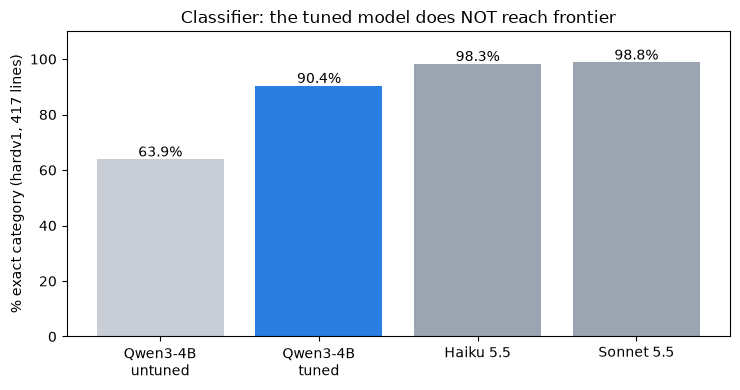

In [6]:
import matplotlib.pyplot as plt
names=["Qwen3-4B\nuntuned","Qwen3-4B\ntuned","Haiku 5.5","Sonnet 5.5"]; vals=[63.9,90.4,98.3,98.8]
cols=["#c9ced6","#2a7de1","#9aa5b1","#9aa5b1"]
fig,ax=plt.subplots(figsize=(7.5,4)); b=ax.bar(names,vals,color=cols)
for r,a in zip(b,vals): ax.text(r.get_x()+r.get_width()/2,a+1,f"{a}%",ha="center")
ax.set_ylim(0,110); ax.set_ylabel("% exact category (hardv1, 417 lines)")
ax.set_title("Classifier: the tuned model does NOT reach frontier"); plt.tight_layout(); plt.show()

## 11. Sonnet 5.5 as reviewer and reference-style evaluation (2026-10-29)
**Sonnet 5.5** was run with the same prompt and the same 275 histories. It is scored as in the industry case study (Part 2): fixed benchmark, same task for everyone, deterministic score, per-*receipt* metrics and **dollar-weighted recall**.
Honest reading: the tuned model wins on per-history recall and false alarms; Sonnet wins on per-receipt precision and on dollars. **There is no clean winner.**

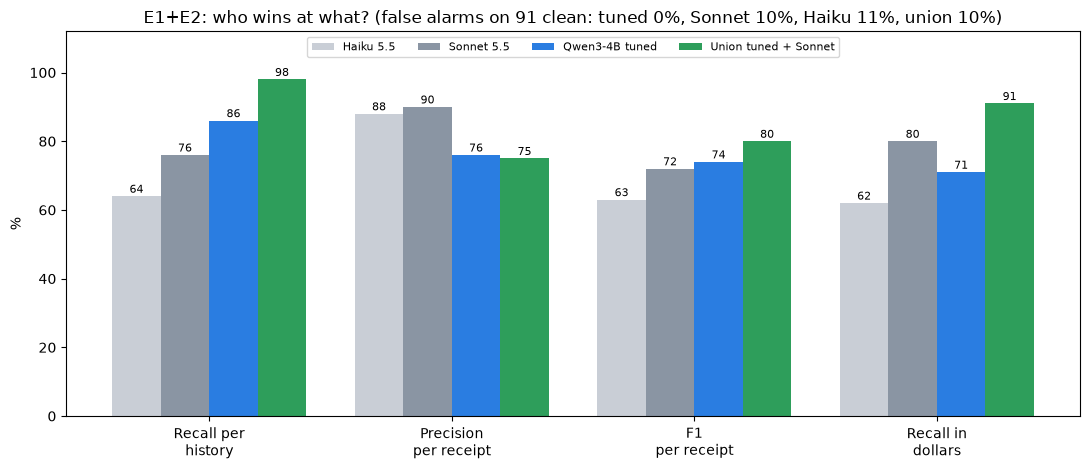

In [7]:
import matplotlib.pyplot as plt, numpy as np
# E1+E2 (144 unseen histories). Source: pipeline/score_full.py
M=["Recall per\nhistory","Precision\nper receipt","F1\nper receipt","Recall in\ndollars"]
data={"Haiku 5.5":[64,88,63,62],"Sonnet 5.5":[76,90,72,80],"Qwen3-4B tuned":[86,76,74,71],"Union tuned + Sonnet":[98,75,80,91]}
cols=["#c9ced6","#8a95a3","#2a7de1","#2e9e5b"]
x=np.arange(len(M)); w=.2
fig,ax=plt.subplots(figsize=(11,4.8))
for i,(k,v) in enumerate(data.items()):
    b=ax.bar(x+(i-1.5)*w,v,w,label=k,color=cols[i])
    for r,a in zip(b,v): ax.text(r.get_x()+r.get_width()/2,a+1,str(a),ha="center",fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(M); ax.set_ylim(0,112); ax.set_ylabel("%"); ax.legend(ncol=4,loc="upper center",fontsize=8)
ax.set_title("E1+E2: who wins at what? (false alarms on 91 clean: tuned 0%, Sonnet 10%, Haiku 11%, union 10%)")
plt.tight_layout(); plt.show()

In [8]:
import pandas as pd
rows=[['competing_saas_tool_sampling', 'E1', 7, 6, 2, 376, 309, 112], ['day_trip_with_lodging', 'E1', 7, 7, 7, 1602, 576, 1081], ['identical_booking_fee_across_rides', 'E1', 7, 7, 0, 827, 769, 0], ['office_purchases_exact_multiples', 'E1', 7, 7, 2, 1250, 900, 440], ['price_creep_same_item_weekly', 'E1', 7, 7, 3, 1103, 1103, 463], ['streaming_rig_from_accessories', 'E1', 7, 7, 7, 2443, 2411, 2443], ['teleporting_employee', 'E1', 7, 7, 4, 1841, 1086, 185], ['tip_and_service_charge_double_dip', 'E1', 7, 7, 4, 1074, 1074, 629], ['trip_id_recycled_for_commuting', 'E1', 7, 5, 7, 779, 513, 507], ['trip_id_stretched_over_month', 'E1', 7, 6, 5, 783, 285, 333], ['two_places_one_day', 'E1', 7, 7, 6, 772, 426, 368], ['weekend_stay_beyond_trip', 'E1', 7, 1, 7, 2649, 375, 2122], ['duplicate_submission', 'E2', 22, 20, 19, 573, 543, 518], ['meal_just_under_doc', 'E2', 22, 20, 22, 12347, 11461, 12347], ['pa_reuse', 'E2', 16, 10, 14, 22442, 14063, 18911], ['gift_splitting', 'E3', 10, 10, 10, 1722, 1722, 1722], ['gift_under_naming', 'E3', 9, 9, 7, 473, 467, 389], ['itemize_just_under', 'E3', 5, 3, 5, 1178, 739, 1178], ['meal_cap_hugging', 'E3', 6, 6, 6, 2123, 2064, 2123], ['tech_just_under', 'E3', 10, 10, 10, 8290, 8095, 8290]]
df=pd.DataFrame(rows,columns=["scheme","set","histories","tuned","Sonnet","$ fraud","$ tuned","$ Sonnet"])
df["tuned %"]=(100*df.tuned/df.histories).round(); df["Sonnet %"]=(100*df.Sonnet/df.histories).round()
def color(v): return "background-color:#d6f5e1" if v>=85 else ("background-color:#fff3c4" if v>=50 else "background-color:#f9d3d3")
display(df[["set","scheme","histories","tuned","tuned %","Sonnet","Sonnet %","$ fraud","$ tuned","$ Sonnet"]].style.map(color,subset=["tuned %","Sonnet %"]))

,set,scheme,histories,tuned,tuned %,Sonnet,Sonnet %,$ fraud,$ tuned,$ Sonnet
0,E1,competing_saas_tool_sampling,7,6,86.000000,2,29.000000,376,309,112
1,E1,day_trip_with_lodging,7,7,100.000000,7,100.000000,1602,576,1081
2,E1,identical_booking_fee_across_rides,7,7,100.000000,0,0.000000,827,769,0
3,E1,office_purchases_exact_multiples,7,7,100.000000,2,29.000000,1250,900,440
4,E1,price_creep_same_item_weekly,7,7,100.000000,3,43.000000,1103,1103,463
5,E1,streaming_rig_from_accessories,7,7,100.000000,7,100.000000,2443,2411,2443
6,E1,teleporting_employee,7,7,100.000000,4,57.000000,1841,1086,185
7,E1,tip_and_service_charge_double_dip,7,7,100.000000,4,57.000000,1074,1074,629
8,E1,trip_id_recycled_for_commuting,7,5,71.000000,7,100.000000,779,513,507
9,E1,trip_id_stretched_over_month,7,6,86.000000,5,71.000000,783,285,333


### What the per-scheme table shows (detected / histories)
- **Complementary:** the tuned model fails `weekend_stay_beyond_trip` (1/7) and `pa_reuse` (10/16), exactly where Sonnet succeeds; Sonnet fails `identical_booking_fee_across_rides` (0/7) and `competing_saas_tool_sampling` (2/7), where the tuned model succeeds.
- **The money is concentrated:** `pa_reuse` (<span class="tex2jax_ignore">&#36;</span>22k) and `meal_just_under_doc` (<span class="tex2jax_ignore">&#36;</span>12k) weigh more than all the others together. That is why the tuned model's dollar recall (71%) sits below Sonnet's (80%) even though it detects more histories.
- **Union (tuned OR Sonnet):** since the reviewer can only *escalate*, combining the two is safe: recall 98% per history, 91% in dollars, F1 80. The cost: false alarms are Sonnet's (10%). It is no longer "the small model beats the frontier", it is "the small one complements the frontier".

## 12. Plan to improve it (proposed; in priority order)
| # | Improvement | Why (evidence) | Cost |
|---|---|---|---|
| 1 | **More independent evaluation**: a new set with schemes written by another process (another model, a human) and frozen before training | Everything comes from the same generator; it is the biggest doubt about the result | low |
| 2 | **Fair frontier**: Sonnet with 3 runs and with a prompt with examples | Today it is a single run with a prompt without examples | low |
| 3 | **Train with dollar weighting** and more examples of `pa_reuse`, `weekend_stay`, `itemize_just_under` | That is where the failures and most of the money are | ~5 h of mini |
| 4 | **Raise low precision**: examples where only the key receipt is escalated, not the whole pattern | Per-receipt precision 76% vs Sonnet's 90% | ~5 h of mini |
| 5 | **Seeds**: 3 training runs and report the range | Today it is a single run | ~15 h |
| 6 | **RLVR (GRPO) as in the industry case study** with a deterministic reward per receipt and per dollar | It is the method of the article; SFT is the fallback | uncertain on 16 GB |
Success criterion for "I beat the frontier" (set before measuring): per-history recall and dollar recall ≥ Sonnet with non-overlapping intervals, false alarms ≤ 5%, on a frozen, independent set.